# 03 — Preprocessing, models and evaluation
All fitted preprocessing sits inside a `Pipeline`, so it is fitted on training data only (and refitted in each CV fold). The test set is used once, at the end.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv("../data/processed/hdi_classification_2023.csv")

NUM = ["GDP_growth", "Inflation", "Unemployment", "Infant_mortality", "Electricity_access",
       "Internet_users", "Agriculture_VA", "Industry_VA", "Trade"]
CAT = ["Region", "DominantSector"]
CLASSES = ["Low", "Medium/High", "Very High"]

# predictors only: no HDI, no country name or code
X = df[NUM + CAT]
y = df["y"]

## 1. Stratified 60/20/20 split

In [3]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=42)

pd.DataFrame({"train": y_train.value_counts(), "val": y_val.value_counts(), "test": y_test.value_counts()})

,train,val,test
y,,,
1,55,19,19
2,44,15,15
0,16,5,5


## 2. Preprocessing
Numerical: impute, then standardise. Categorical: impute, then one-hot encode (unseen categories are ignored).

In [4]:
def make_preprocessor(num_cols, cat_cols, num_strategy="median", add_indicator=False, cat_strategy="constant"):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy=num_strategy, add_indicator=add_indicator)),
        ("scaler", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy=cat_strategy, fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)],
                             verbose_feature_names_out=False)

### Imputation comparison
Logistic regression with default settings; 5-fold CV macro-F1 on the training set.

In [5]:
rows = []
for num_strategy in ["median", "mean"]:
    for add_indicator in [False, True]:
        for cat_strategy in ["constant", "most_frequent"]:
            model = Pipeline([
                ("pre", make_preprocessor(NUM, CAT, num_strategy, add_indicator, cat_strategy)),
                ("clf", LogisticRegression(max_iter=5000)),
            ])
            scores = cross_val_score(model, X_train, y_train, cv=5, scoring="f1_macro")
            rows.append([num_strategy, add_indicator, cat_strategy, scores.mean(), scores.std()])

pd.DataFrame(rows, columns=["numeric", "indicator", "categorical", "cv_f1_mean", "cv_f1_std"])

,numeric,indicator,categorical,cv_f1_mean,cv_f1_std
0,median,False,constant,0.813633,0.107363
1,median,False,most_frequent,0.813633,0.107363
2,median,True,constant,0.794057,0.105681
3,median,True,most_frequent,0.794057,0.105681
4,mean,False,constant,0.799581,0.099664
5,mean,False,most_frequent,0.799581,0.099664
6,mean,True,constant,0.794057,0.105681
7,mean,True,most_frequent,0.794057,0.105681


All differences are smaller than one CV standard deviation. We use median imputation (robust to outliers), no missingness indicators, and an explicit "Missing" category.

## 3. PCA (fitted on training data)

In [6]:
pre = make_preprocessor(NUM, CAT)
Z_train = pre.fit_transform(X_train)
pca = PCA().fit(Z_train)

pca.explained_variance_ratio_.cumsum()

array([0.37979893, 0.49968244, 0.61698625, 0.72192845, 0.80384836,
       0.8792504 , 0.90393689, 0.92746708, 0.94473001, 0.9586806 ,
       0.97118301, 0.97947732, 0.98735923, 0.9930879 , 0.99602798,
       0.99793508, 0.99930113, 1.        , 1.        , 1.        ])

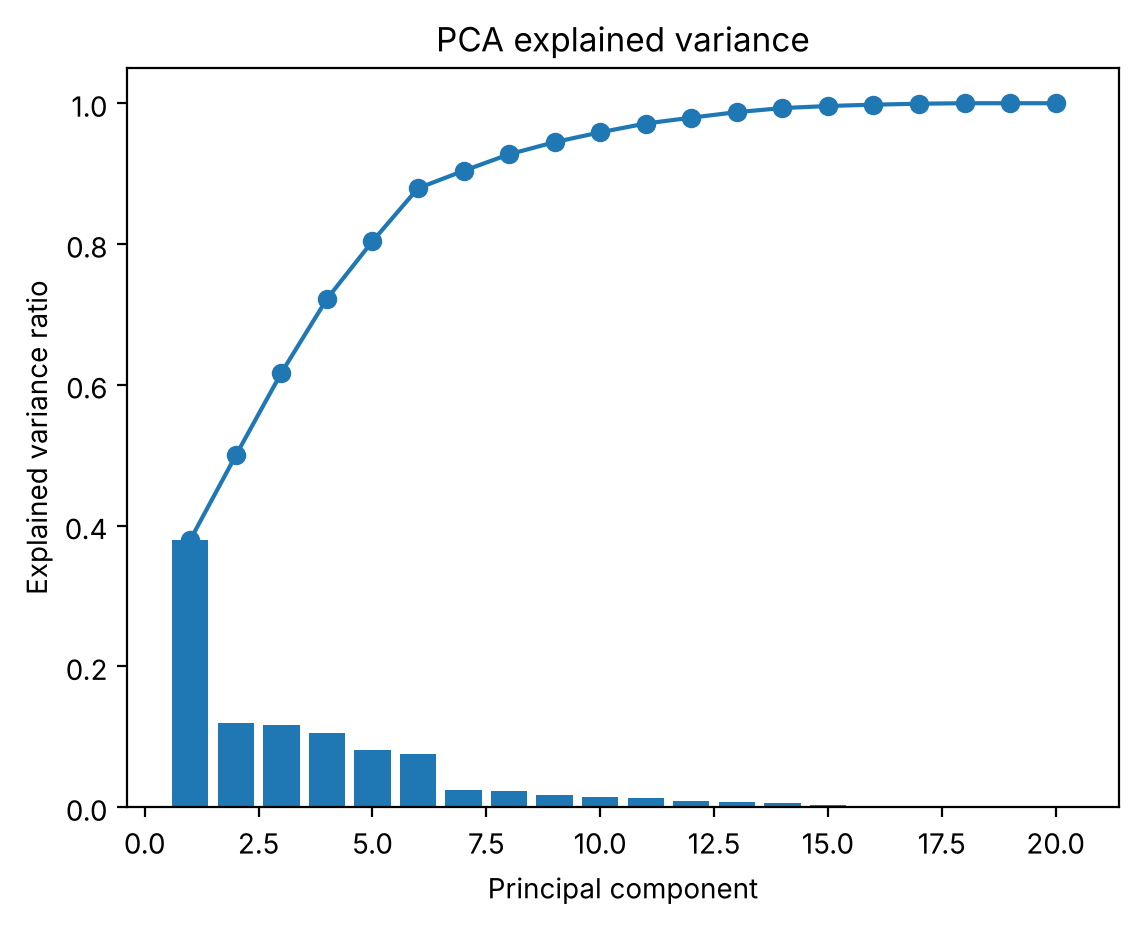

In [7]:
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_)
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_.cumsum(), "o-")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA explained variance")
plt.savefig("../figures/pca_explained_variance.png", dpi=200)
plt.show()

In [8]:
loadings = pd.DataFrame(pca.components_[:3].T, index=pre.get_feature_names_out(), columns=["PC1", "PC2", "PC3"])
loadings.round(2)

,PC1,PC2,PC3
GDP_growth,-0.11,-0.30,-0.45
Inflation,-0.05,-0.44,0.59
Unemployment,-0.02,0.10,0.56
Infant_mortality,-0.46,0.12,0.07
Electricity_access,0.47,-0.06,0.05
Internet_users,0.49,0.03,0.03
Agriculture_VA,-0.46,-0.05,-0.15
Industry_VA,0.07,0.78,-0.02
Trade,0.24,-0.22,-0.31
Region_East Asia & Pacific,0.03,0.01,-0.08


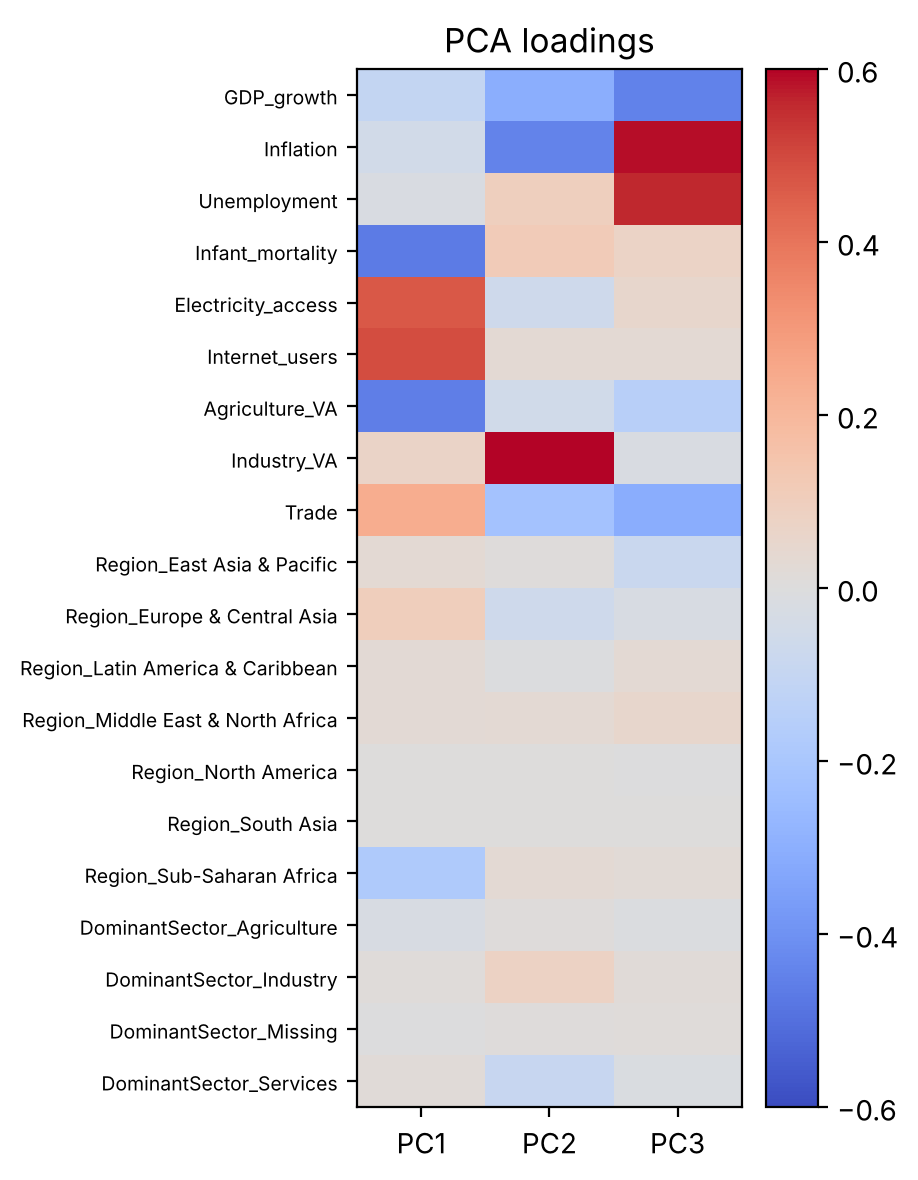

In [9]:
plt.figure(figsize=(4.5, 6))
plt.imshow(loadings, cmap="coolwarm", vmin=-0.6, vmax=0.6, aspect="auto")
plt.yticks(range(len(loadings)), loadings.index, fontsize=7)
plt.xticks(range(3), loadings.columns)
plt.colorbar()
plt.title("PCA loadings")
plt.tight_layout()
plt.savefig("../figures/pca_loadings.png", dpi=200)
plt.show()

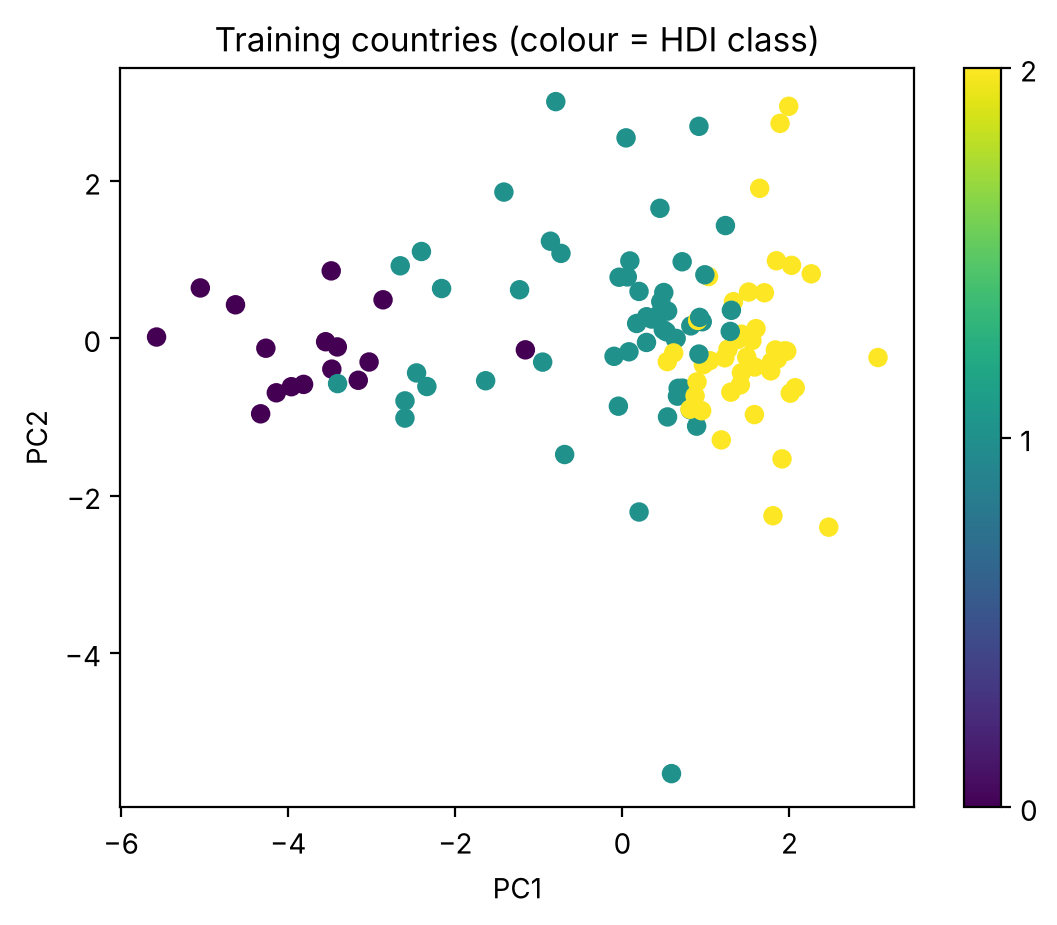

In [10]:
pcs = pca.transform(Z_train)
plt.scatter(pcs[:, 0], pcs[:, 1], c=y_train, cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Training countries (colour = HDI class)")
plt.colorbar(ticks=[0, 1, 2])
plt.savefig("../figures/pca_scatter.png", dpi=200)
plt.show()

## 4. Models
Tuned with `GridSearchCV` (stratified 5-fold CV on the training set, macro-F1), then compared on the validation set. The PCA grid uses 2, 3, 5 and 7 components; 7 components explain at least 90% of the variance.

In [11]:
models = {
    "Baseline": (
        Pipeline([("pre", make_preprocessor(NUM, CAT)), ("clf", DummyClassifier(strategy="most_frequent"))]),
        {}),
    "Logistic regression": (
        Pipeline([("pre", make_preprocessor(NUM, CAT)), ("clf", LogisticRegression(max_iter=5000))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Decision tree": (
        Pipeline([("pre", make_preprocessor(NUM, CAT)), ("clf", DecisionTreeClassifier(random_state=42))]),
        {"clf__max_depth": [2, 3, 4, 5, None], "clf__min_samples_leaf": [1, 3, 5]}),
    "Random forest": (
        Pipeline([("pre", make_preprocessor(NUM, CAT)), ("clf", RandomForestClassifier(n_estimators=300, random_state=42))]),
        {"clf__max_depth": [None, 3, 5], "clf__min_samples_leaf": [1, 3]}),
    "LR + PCA": (
        Pipeline([("pre", make_preprocessor(NUM, CAT)), ("pca", PCA(random_state=42)), ("clf", LogisticRegression(max_iter=5000))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100], "pca__n_components": [2, 3, 5, 7]}),
    "RF + PCA": (
        Pipeline([("pre", make_preprocessor(NUM, CAT)), ("pca", PCA(random_state=42)), ("clf", RandomForestClassifier(n_estimators=300, random_state=42))]),
        {"clf__max_depth": [None, 3, 5], "clf__min_samples_leaf": [1, 3], "pca__n_components": [2, 3, 5, 7]}),
}

fitted = {}
rows = []
for name in models:
    model, grid = models[name]
    search = GridSearchCV(model, grid, cv=5, scoring="f1_macro")
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    cv_std = search.cv_results_["std_test_score"][search.best_index_]
    val_f1 = f1_score(y_val, search.predict(X_val), average="macro")
    rows.append([name, search.best_params_, search.best_score_, cv_std, val_f1])

pd.DataFrame(rows, columns=["model", "best_params", "cv_f1_mean", "cv_f1_std", "val_f1"])

,model,best_params,cv_f1_mean,cv_f1_std,val_f1
0,Baseline,{},0.215686,2.775558e-17,0.218391
1,Logistic regression,{'clf__C': 10},0.858049,6.880571e-02,0.798549
2,Decision tree,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 3}",0.765062,2.269021e-01,0.736713
3,Random forest,"{'clf__max_depth': 3, 'clf__min_samples_leaf': 1}",0.857808,1.061878e-01,0.755260
4,LR + PCA,"{'clf__C': 100, 'pca__n_components': 5}",0.864092,8.163790e-02,0.783333
5,RF + PCA,"{'clf__max_depth': None, 'clf__min_samples_lea...",0.864837,4.820943e-02,0.755788


Logistic regression has the highest validation macro-F1, so it is the selected model. PCA does not clearly improve or hurt performance.

## 5. Feature-set comparison

In [12]:
feature_sets = [
    ["numerical only", NUM, []],
    ["categorical only", [], CAT],
    ["numerical + Region", NUM, ["Region"]],
    ["numerical + DominantSector", NUM, ["DominantSector"]],
    ["combined", NUM, CAT],
]

rows = []
for set_name, num_cols, cat_cols in feature_sets:
    lr = Pipeline([("pre", make_preprocessor(num_cols, cat_cols)), ("clf", LogisticRegression(max_iter=5000))])
    rf = Pipeline([("pre", make_preprocessor(num_cols, cat_cols)), ("clf", RandomForestClassifier(n_estimators=300, random_state=42))])

    lr_search = GridSearchCV(lr, {"clf__C": [0.01, 0.1, 1, 10, 100]}, cv=5, scoring="f1_macro")
    rf_search = GridSearchCV(rf, {"clf__max_depth": [None, 3, 5], "clf__min_samples_leaf": [1, 3]}, cv=5, scoring="f1_macro")
    lr_search.fit(X_train[num_cols + cat_cols], y_train)
    rf_search.fit(X_train[num_cols + cat_cols], y_train)

    rows.append([set_name, lr_search.best_score_, rf_search.best_score_])

feature_results = pd.DataFrame(rows, columns=["feature set", "LR cv_f1", "RF cv_f1"])
feature_results

,feature set,LR cv_f1,RF cv_f1
0,numerical only,0.860436,0.861091
1,categorical only,0.523548,0.527400
2,numerical + Region,0.861974,0.847202
3,numerical + DominantSector,0.851105,0.874552
4,combined,0.858049,0.857808


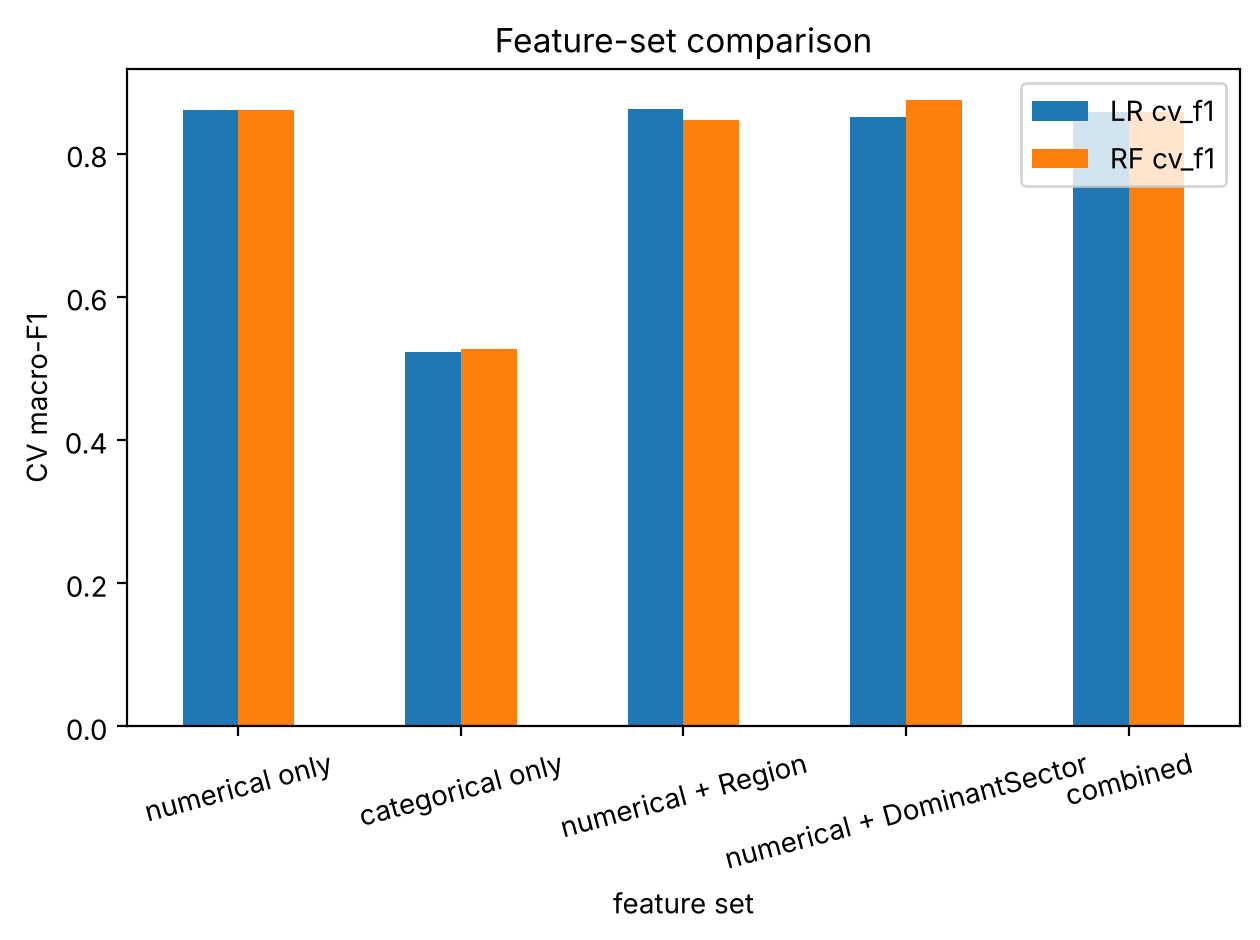

In [13]:
feature_results.plot.bar(x="feature set", rot=15)
plt.ylabel("CV macro-F1")
plt.title("Feature-set comparison")
plt.tight_layout()
plt.savefig("../figures/feature_set_comparison.png", dpi=200)
plt.show()

## 6. Test-set evaluation (used once)

In [14]:
rows = []
for name in fitted:
    pred = fitted[name].predict(X_test)
    rows.append([name, accuracy_score(y_test, pred), balanced_accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")])

pd.DataFrame(rows, columns=["model", "accuracy", "balanced_accuracy", "macro_f1"])

,model,accuracy,balanced_accuracy,macro_f1
0,Baseline,0.487179,0.333333,0.218391
1,Logistic regression,0.794872,0.658480,0.662580
2,Decision tree,0.794872,0.600000,0.563741
3,Random forest,0.794872,0.609357,0.591680
4,LR + PCA,0.820513,0.676023,0.681595
5,RF + PCA,0.794872,0.658480,0.662580


In [15]:
for name in ["Logistic regression", "Decision tree", "Random forest"]:
    print(name)
    print(classification_report(y_test, fitted[name].predict(X_test), target_names=CLASSES, zero_division=0))

Logistic regression
              precision    recall  f1-score   support

         Low       0.25      0.20      0.22         5
 Medium/High       0.76      0.84      0.80        19
   Very High       1.00      0.93      0.97        15

    accuracy                           0.79        39
   macro avg       0.67      0.66      0.66        39
weighted avg       0.79      0.79      0.79        39

Decision tree
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         5
 Medium/High       0.76      1.00      0.86        19
   Very High       0.86      0.80      0.83        15

    accuracy                           0.79        39
   macro avg       0.54      0.60      0.56        39
weighted avg       0.70      0.79      0.74        39

Random forest
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         5
 Medium/High       0.74      0.89      0.81        19
   Very High       1.00    

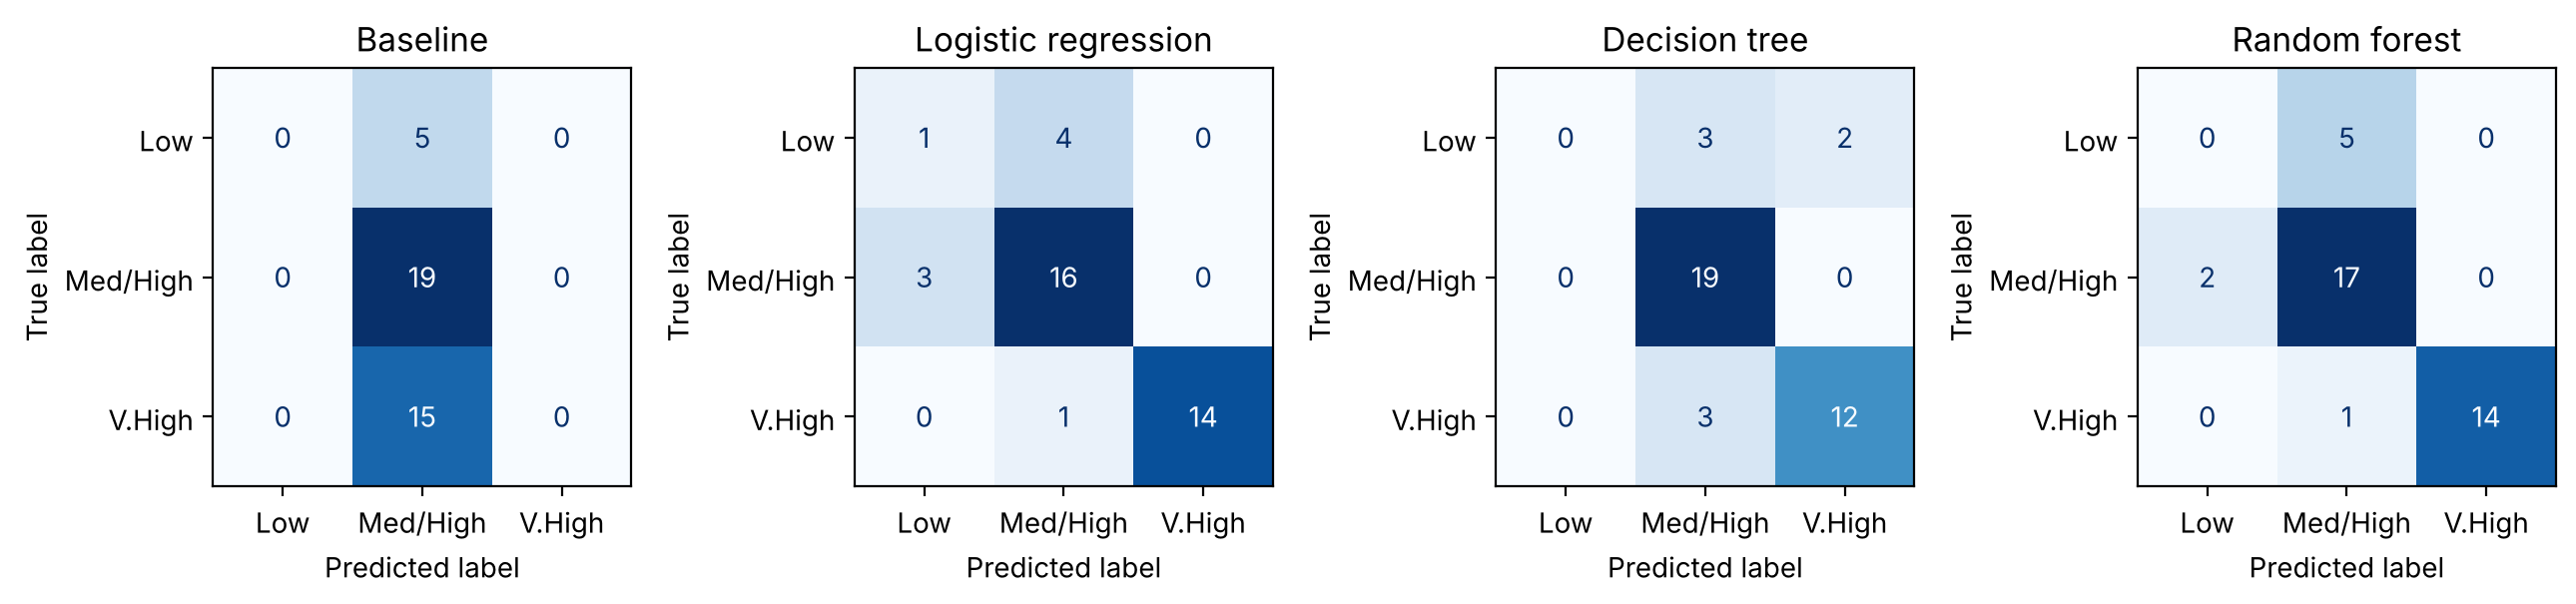

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, name in zip(axes, ["Baseline", "Logistic regression", "Decision tree", "Random forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, display_labels=["Low", "Med/High", "V.High"],
                                          ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../figures/confusion_matrices.png", dpi=200)
plt.show()

## 7. Interpretation
### Logistic-regression coefficients
Inputs are standardised, so each coefficient is the change in a class score per one standard deviation. Predictors are correlated, so individual coefficients should be read with caution.

In [17]:
lr = fitted["Logistic regression"]
coef = pd.DataFrame(lr.named_steps["clf"].coef_.T, index=lr.named_steps["pre"].get_feature_names_out(), columns=CLASSES)
coef.round(2)

,Low,Medium/High,Very High
GDP_growth,0.12,-0.42,0.30
Inflation,-0.34,0.40,-0.06
Unemployment,-0.08,0.05,0.03
Infant_mortality,2.58,1.23,-3.81
Electricity_access,-1.67,1.81,-0.15
Internet_users,-1.33,-1.17,2.50
Agriculture_VA,2.09,0.62,-2.72
Industry_VA,-0.48,0.34,0.14
Trade,-1.26,0.24,1.02
Region_East Asia & Pacific,-0.11,0.99,-0.88


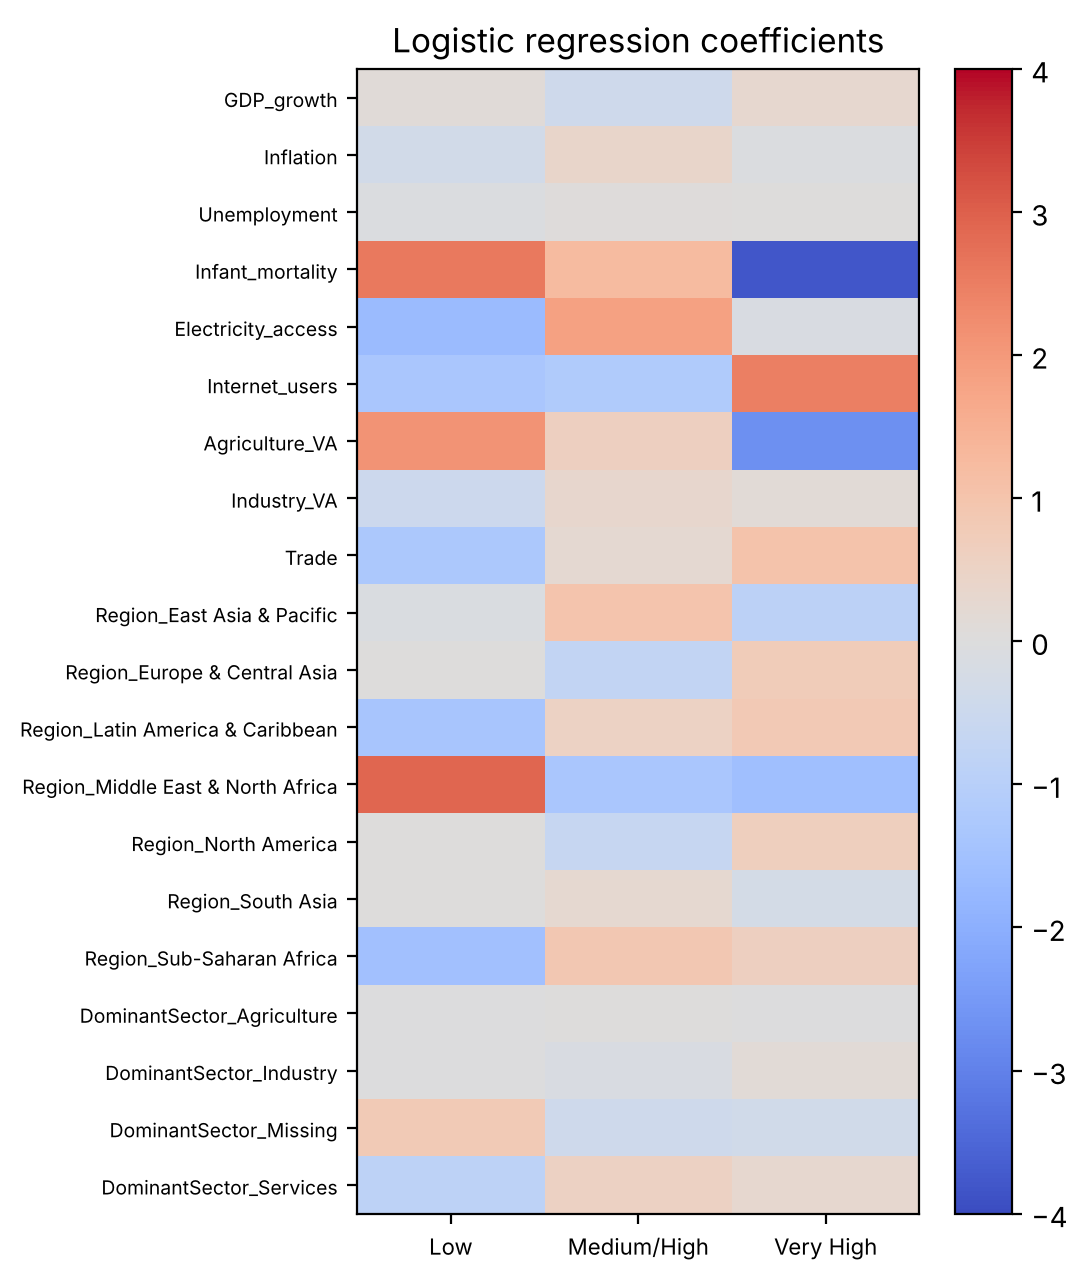

In [18]:
plt.figure(figsize=(5.5, 6.5))
plt.imshow(coef, cmap="coolwarm", vmin=-4, vmax=4, aspect="auto")
plt.yticks(range(len(coef)), coef.index, fontsize=7)
plt.xticks(range(3), CLASSES, fontsize=8)
plt.colorbar()
plt.title("Logistic regression coefficients")
plt.tight_layout()
plt.savefig("../figures/lr_coefficients.png", dpi=200)
plt.show()

### Random-forest permutation importance (test set)

In [19]:
result = permutation_importance(fitted["Random forest"], X_test, y_test, scoring="f1_macro", n_repeats=30, random_state=42)
importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values()
importance

Electricity_access   -0.026315
GDP_growth           -0.005214
Trade                -0.001523
Region               -0.001194
DominantSector        0.000000
Industry_VA           0.004532
Unemployment          0.006222
Inflation             0.013111
Internet_users        0.018605
Agriculture_VA        0.019217
Infant_mortality      0.077322
dtype: float64

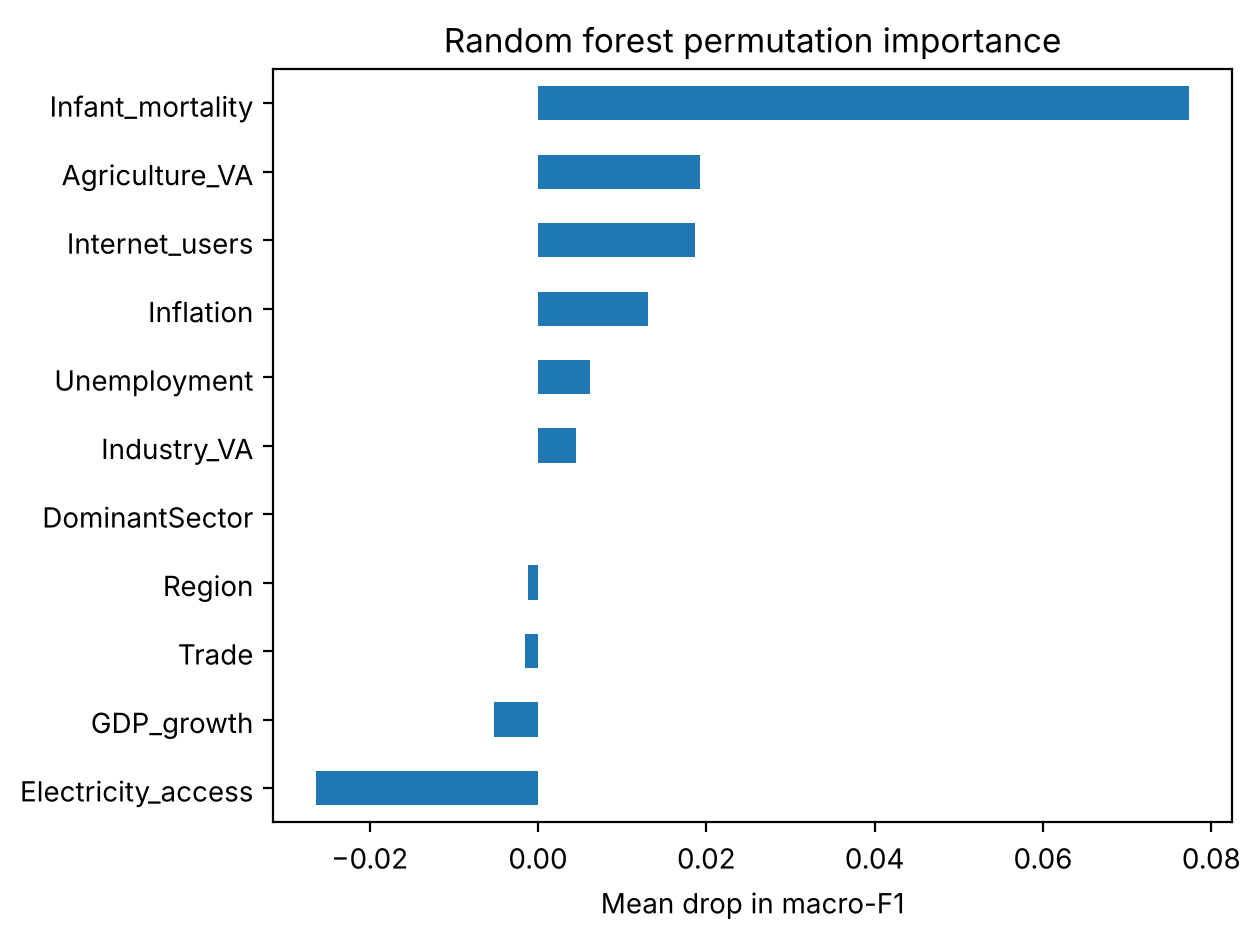

In [20]:
importance.plot.barh()
plt.xlabel("Mean drop in macro-F1")
plt.title("Random forest permutation importance")
plt.tight_layout()
plt.savefig("../figures/rf_permutation_importance.png", dpi=200)
plt.show()

### Decision tree (thresholds are standardised values)

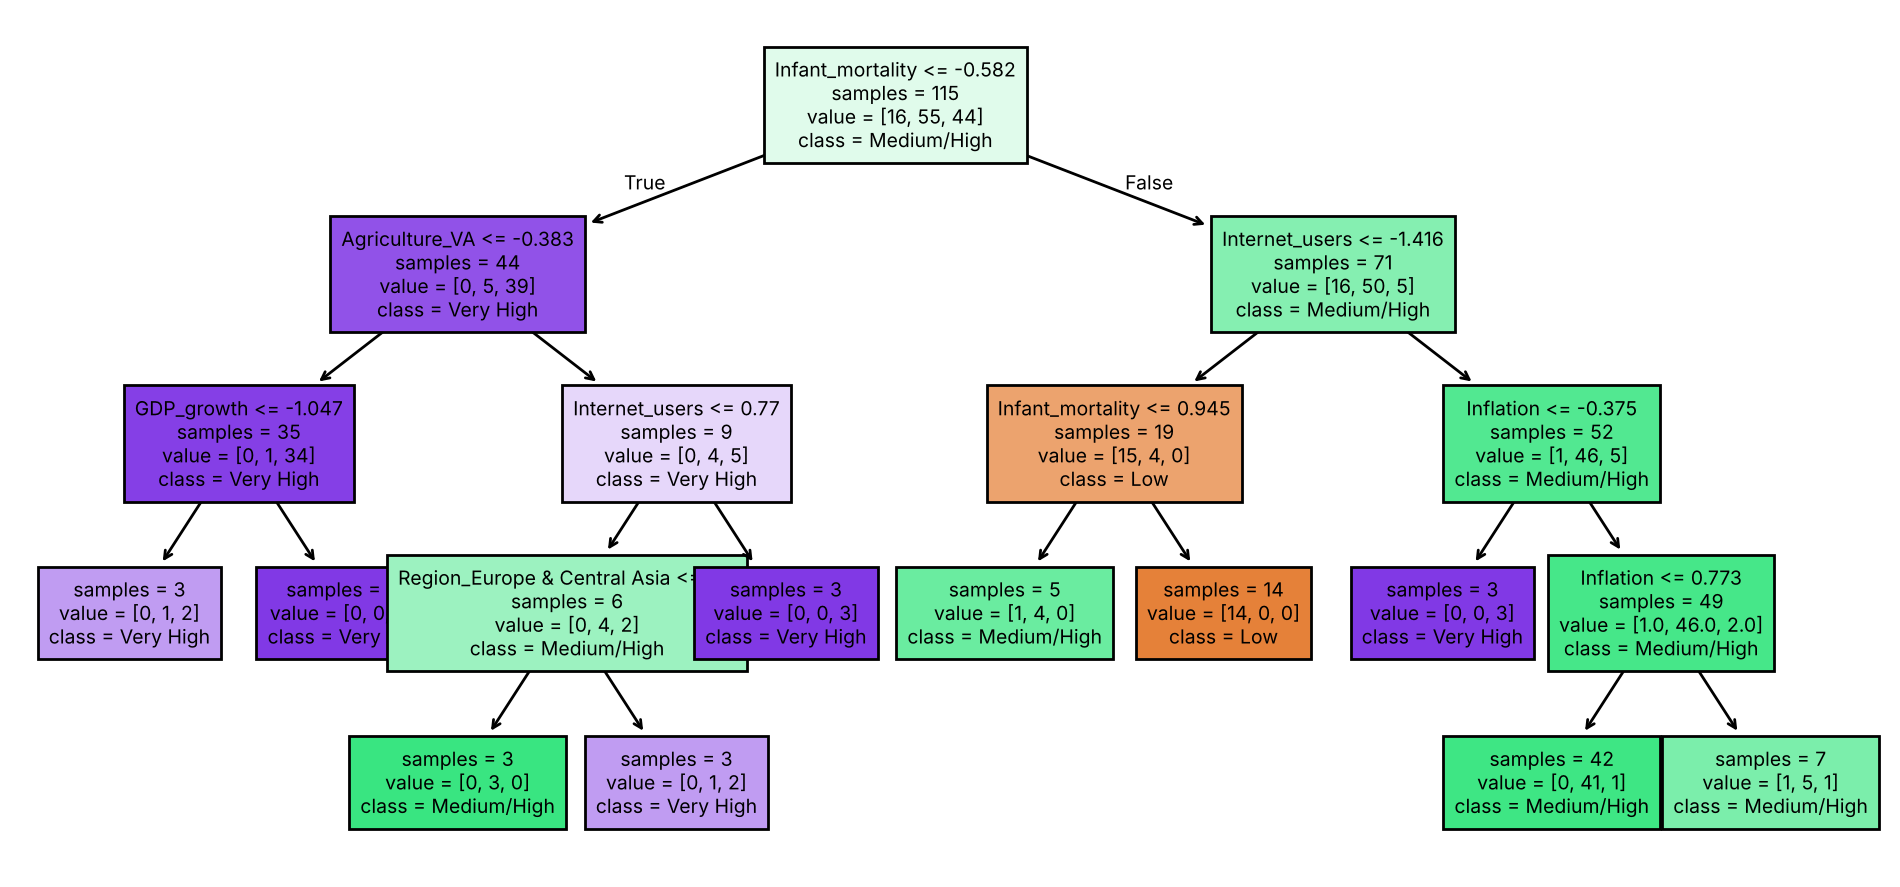

In [21]:
dt = fitted["Decision tree"]
plt.figure(figsize=(12, 5.5))
plot_tree(dt.named_steps["clf"], feature_names=dt.named_steps["pre"].get_feature_names_out(),
          class_names=CLASSES, filled=True, impurity=False, fontsize=7)
plt.savefig("../figures/decision_tree.png", dpi=200)
plt.show()

### Misclassified test countries

In [22]:
names = {0: "Low", 1: "Medium/High", 2: "Very High"}
test_countries = df.loc[X_test.index, ["Country", "HDI", "HDI_class"]]
test_countries["LR"] = pd.Series(fitted["Logistic regression"].predict(X_test), index=X_test.index).map(names)
test_countries["DT"] = pd.Series(fitted["Decision tree"].predict(X_test), index=X_test.index).map(names)
test_countries["RF"] = pd.Series(fitted["Random forest"].predict(X_test), index=X_test.index).map(names)

wrong = (test_countries["LR"] != test_countries["HDI_class"]) | \
        (test_countries["DT"] != test_countries["HDI_class"]) | \
        (test_countries["RF"] != test_countries["HDI_class"])
test_countries[wrong].sort_values("HDI")

,Country,HDI,HDI_class,LR,DT,RF
114,Mali,0.419,Low,Low,Very High,Medium/High
52,Eritrea,0.503,Low,Medium/High,Medium/High,Medium/High
149,Sudan,0.511,Low,Medium/High,Medium/High,Medium/High
45,Djibouti,0.513,Low,Medium/High,Very High,Medium/High
65,"Gambia, The",0.524,Low,Medium/High,Medium/High,Medium/High
178,Tanzania,0.555,Medium/High,Low,Medium/High,Low
139,Papua New Guinea,0.576,Medium/High,Low,Medium/High,Medium/High
179,Uganda,0.582,Medium/High,Low,Medium/High,Low
18,"Bahamas, The",0.820,Very High,Very High,Medium/High,Very High
93,St. Kitts and Nevis,0.840,Very High,Medium/High,Medium/High,Medium/High
